# 04 — Avaliação e Interpretação

**Objetivo.** Conferir, em clientes que nenhum modelo viu, se o desempenho medido na
validação cruzada se sustenta; entender o que o modelo aprendeu; e traduzir o resultado em
decisão de crédito.

O conjunto de teste (20% dos clientes) foi separado no início do notebook 03 e é usado aqui
pela primeira e única vez. Modelo, hiperparâmetros e limiar já estavam definidos antes.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # permite `from src... import ...`

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             roc_auc_score)

from src.config import COR_BOM, COR_MAU, COR_NEUTRA, FEATURE_SETS, GROUP, METRICS, MODELS, ROTULOS
from src.data import load_processed
from src.evaluation import (band_table, bootstrap_ci, comparison_table, cv_permutation_importance,
                            policy_table, score)
from src.models import build_preprocessor, cross_validate_model, split_train_test
from src.plots import roc_pr_curves, save, set_style

# Semente fixa: usada em TODO ponto com aleatoriedade (split, modelos, CV).
RANDOM_STATE = 42

RAW = Path("..") / "data" / "raw"
PROCESSED = Path("..") / "data" / "processed"
TARGET = "MAU_PAGADOR"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
set_style()

In [2]:
df = load_processed()
train, test = split_train_test(df, random_state=RANDOM_STATE)   # mesmo split do notebook 03
meta = json.load(open(METRICS / "modelos_treinados.json"))
modelos = {nome: joblib.load(MODELS / f"{nome}.joblib") for nome in meta["modelos"]}
ESCOLHIDO = meta["modelo_escolhido"]
y_test = test[TARGET].to_numpy()
print("Modelo escolhido no notebook 03:", ESCOLHIDO)
print(f"Teste: {len(test):,} contas de {test[GROUP].nunique():,} clientes | "
      f"{y_test.sum()} maus ({y_test.mean():.2%})")

Modelo escolhido no notebook 03: logistic_regression
Teste: 4,914 contas de 1,576 clientes | 74 maus (1.51%)


## 1. Métricas no conjunto de teste

In [3]:
proba, resultados = {}, {}
for nome, modelo in modelos.items():
    info = meta["modelos"][nome]
    proba[nome] = modelo.predict_proba(test[info["atributos"]])[:, 1]
    pred = (proba[nome] >= info["limiar_f1"]).astype(int)
    lo, hi = bootstrap_ci(y_test, proba[nome], test[GROUP], random_state=RANDOM_STATE)
    resultados[nome] = {**score(y_test, pred, proba[nome]), "roc_auc_ic95_inf": lo,
                        "roc_auc_ic95_sup": hi, "roc_auc_cv": info["cv_roc_auc"],
                        "limiar": info["limiar_f1"]}
tabela = comparison_table(resultados, name="comparacao_modelos", sort_by="roc_auc")
tabela

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,ks,roc_auc_ic95_inf,roc_auc_ic95_sup,roc_auc_cv,limiar
logistic_regression,0.9723,0.5734,0.1395,0.1622,0.1500,0.7338,0.0838,0.3720,0.6622,0.7989,0.7513,0.7676
random_forest,0.9715,0.5930,0.1562,0.2027,0.1765,0.7241,0.0960,0.3887,0.6520,0.7973,0.7611,0.5720
gradient_boosting,0.9742,0.5810,0.1646,0.1757,0.1699,0.7118,0.0815,0.3380,0.6370,0.7833,0.7549,0.6895
knn,0.9764,0.5356,0.1111,0.0811,0.0938,0.7088,0.0471,0.3582,0.6372,0.7790,0.7103,0.0596
decision_tree,0.9742,0.5810,0.1646,0.1757,0.1699,0.6976,0.0608,0.3177,0.6251,0.7665,0.7416,0.8847
random_forest_so_cadastro,0.9654,0.5500,0.0789,0.1216,0.0957,0.6338,0.0605,0.2739,0.5384,0.7230,0.6033,0.4652


Cada linha usa o limiar de máximo F1 definido para aquele modelo com as predições
out-of-fold do treino. `roc_auc_ic95_*` é o intervalo de 95% por bootstrap reamostrando
clientes; `roc_auc_cv` é a estimativa da validação cruzada, para comparação.

**Leitura.**

- **O modelo escolhido (regressão logística, ficha + histórico) marca AUC-ROC de 0,734 no
  teste**, com intervalo de 95% entre 0,66 e 0,80. A validação cruzada estimava 0,751: o
  teste veio um pouco abaixo, dentro do intervalo. O KS é 0,37 e o PR-AUC 0,084, mais de
  cinco vezes o acaso (0,015).
- **O empate entre os melhores se confirma.** A Random Forest marca 0,724 e o Gradient
  Boosting 0,712, com intervalos que se sobrepõem quase por inteiro. A Random Forest fica
  à frente em PR-AUC, KS e F1, a logística em AUC-ROC: com 74 maus no teste, diferenças de
  0,01 ou 0,02 não são mensuráveis em nenhuma direção. Na política de corte (seção 3), os
  dois barram exatamente os mesmos 22 maus no corte de 5%.
- **O ganho do histórico se confirma fora da amostra.** O melhor modelo só com a ficha
  cadastral fica em 0,634, com intervalo que começa em 0,54, perto do acaso.
- **No limiar de referência**, a regressão logística barra 16% dos maus (recall) e acerta 14%
  das reprovações (precisão), com F1 de 0,15. São números baixos em termos absolutos e é
  importante dizê-lo com clareza: o modelo **ordena** risco, não identifica inadimplentes
  um a um.

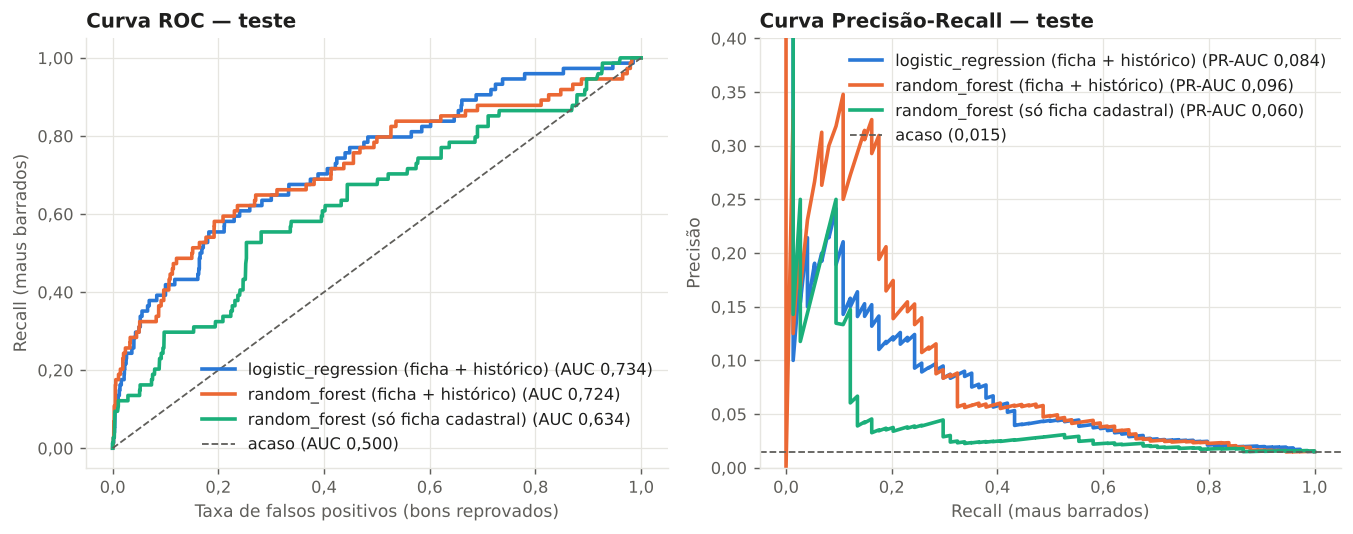

In [4]:
OUTRO = "random_forest" if ESCOLHIDO != "random_forest" else "logistic_regression"
fig = roc_pr_curves({
    f"{ESCOLHIDO} (ficha + histórico)": proba[ESCOLHIDO],
    f"{OUTRO} (ficha + histórico)": proba[OUTRO],
    "random_forest (só ficha cadastral)": proba["random_forest_so_cadastro"],
}, y_test, titulo_extra=" — teste")
save(fig, "04_roc_pr_teste")
plt.show()

**Leitura.** Na curva ROC, os dois modelos com histórico (regressão logística em azul,
Random Forest em laranja) andam juntos e bem acima do modelo só com a ficha (verde), que em vários trechos encosta na diagonal do acaso.
O ganho se concentra no começo da curva: com 10% de bons reprovados, os modelos com
histórico já barram cerca de 40% dos maus. Na curva de precisão-recall, a precisão só é
alta (20% a 30%) para os primeiros 10% a 15% de maus capturados e cai rápido depois: há um
grupo pequeno de pedidos de risco claramente alto e, fora dele, a separação é difícil.

## 2. Justificativa das métricas

**Por que não acurácia.** Com 1,5% de maus, aprovar todos os pedidos dá 98,5% de acurácia
sem barrar um único inadimplente. Todos os modelos da tabela têm acurácia em torno de 97%,
inclusive o que é pouco melhor que o acaso. Ela aparece na tabela por exigência do template,
mas não participa de nenhuma decisão.

**O que foi priorizado, e por quê.**

| Métrica | O que responde | Papel no projeto |
|---|---|---|
| **AUC-ROC** | Sorteando um mau e um bom, qual a chance de o modelo dar escore maior ao mau? | critério de escolha do modelo; não depende de limiar nem da proporção de classes |
| **KS** | Qual a maior distância entre as distribuições de escore de bons e maus? | métrica tradicional de crédito, para comparação com o mercado |
| **PR-AUC** | Qual a precisão média ao longo de todos os níveis de recall? | sensível à classe rara; mostra o quanto o topo do ranking é "limpo" |
| **Recall** (dos maus) | De cada 100 maus, quantos o modelo barra? | mede a perda evitada |
| **Precisão** (dos maus) | De cada 100 reprovados, quantos eram mesmo maus? | mede o custo: clientes bons recusados |
| **F1** | Equilíbrio entre os dois | usado para fixar o limiar de referência |

**Qual erro custa mais.** Os dois erros custam, de formas diferentes:
- **Falso negativo** (aprovar um mau): o banco perde o saldo não pago, potencialmente o
  limite inteiro, mais o custo de cobrança.
- **Falso positivo** (reprovar um bom): o banco deixa de ganhar a receita daquele cliente e
  pode perdê-lo para um concorrente.

Em cartão de crédito a perda com um inadimplente costuma equivaler à margem de muitos bons
clientes, então o falso negativo é o erro mais caro por caso. Mas os bons são 65 vezes mais
numerosos, e um corte agressivo reprova muita gente boa. Por isso não há um limiar "certo"
em abstrato: a tabela de política de corte (seção 3) mostra o que se ganha e o que se perde
em cada nível, para a área de crédito decidir com os próprios números de perda e margem.

## 3. Matriz de confusão

Modelo escolhido, limiar de referência (máximo F1 out-of-fold).

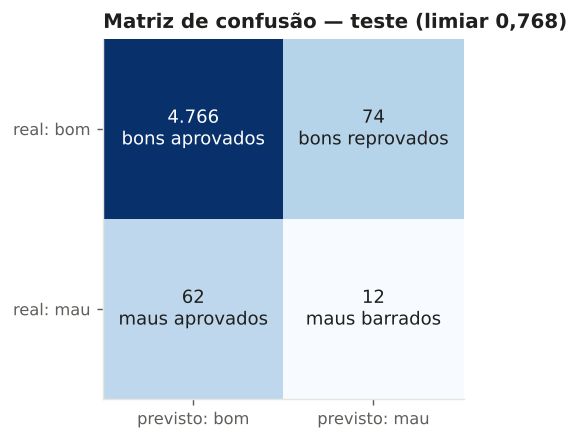

              precision    recall  f1-score   support

 bom pagador      0.987     0.985     0.986      4840
 mau pagador      0.140     0.162     0.150        74

    accuracy                          0.972      4914
   macro avg      0.563     0.573     0.568      4914
weighted avg      0.974     0.972     0.973      4914



In [5]:
limiar = meta["modelos"][ESCOLHIDO]["limiar_f1"]
p = proba[ESCOLHIDO]
pred = (p >= limiar).astype(int)
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.imshow(cm, cmap="Blues", norm="log")
rot = np.array([["bons aprovados", "bons reprovados"], ["maus aprovados", "maus barrados"]])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n{rot[i, j]}".replace(",", "."), ha="center", va="center",
                color="white" if cm[i, j] > 1000 else "#1f1f1e", fontsize=10)
ax.set_xticks([0, 1], ["previsto: bom", "previsto: mau"])
ax.set_yticks([0, 1], ["real: bom", "real: mau"])
ax.set_title(f"Matriz de confusão — teste (limiar {limiar:.3f})".replace(".", ","))
ax.grid(False)
save(fig, "04_matriz_confusao")
plt.show()
print(classification_report(y_test, pred, target_names=["bom pagador", "mau pagador"], digits=3))

**Leitura.** Dos 4.914 pedidos do teste, o modelo reprovaria 86 (1,8%). Entre eles estão **12
dos 74 maus pagadores** (recall de 16%) e 74 bons (precisão de 14%). Os outros 62 maus
passariam. Para cada mau barrado, cerca de seis bons são recusados.

Neste limiar a política é conservadora: mexe em poucos pedidos e remove o grupo de risco
mais evidente. Como o limiar é uma escolha de negócio, as tabelas a seguir mostram outros
pontos de corte.

In [6]:
politica = policy_table(y_test, p)
politica.to_csv(METRICS / "politica_de_corte_teste.csv", index=False)
print(f"Inadimplência do teste sem modelo (aprovando todos): {politica.attrs['inadimplencia_base_pct']:.2f}%")
politica.round(2)

Inadimplência do teste sem modelo (aprovando todos): 1.51%


,reprovados_pct,pedidos_reprovados,maus_barrados,maus_barrados_pct,inadimplencia_reprovados_pct,inadimplencia_aprovados_pct,bons_reprovados_por_mau
0,2.0,98,13,17.57,13.27,1.27,6.54
1,5.0,246,22,29.73,8.94,1.11,10.18
2,10.0,491,29,39.19,5.91,1.02,15.93
3,20.0,983,41,55.41,4.17,0.84,22.98
4,30.0,1474,47,63.51,3.19,0.78,30.36


**Leitura — política de corte.** Cada linha responde: "se o banco reprovar os X% de pedidos
com maior escore de risco, o que acontece?"

| Reprovando | Maus barrados | Inadimplência entre aprovados | Bons recusados por mau barrado |
|---|---|---|---|
| nada | 0% | 1,51% | — |
| 2% | 18% | 1,27% | 7 |
| 5% | 30% | 1,11% | 10 |
| 10% | 39% | 1,02% | 16 |
| 20% | 55% | 0,84% | 23 |
| 30% | 64% | 0,78% | 30 |

Reprovar os 5% de maior risco elimina 30% da inadimplência; reprovar 20% elimina 55%. A
última coluna é o preço: ela diz a partir de que relação entre perda e margem cada corte se
paga. O corte de 5%, por exemplo, vale a pena se a perda com um mau pagador for maior que a
margem de 10 bons clientes. No treino (out-of-fold, notebook 03) o mesmo corte barrou 25%
dos maus: o teste ficou um pouco acima, dentro da margem de erro de 74 eventos.

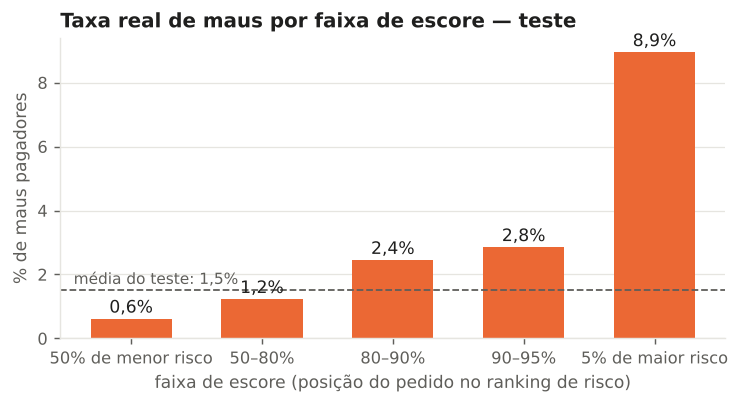

,pedidos,maus,taxa_maus_pct,maus_do_total_pct
50% de menor risco,2457,15,0.61,20.27
50–80%,1474,18,1.22,24.32
80–90%,491,12,2.44,16.22
90–95%,246,7,2.85,9.46
5% de maior risco,246,22,8.94,29.73


In [7]:
faixas = band_table(y_test, p, cortes=[0.5, 0.8, 0.9, 0.95])
faixas.index = ["50% de menor risco", "50–80%", "80–90%", "90–95%", "5% de maior risco"]
faixas.to_csv(METRICS / "faixas_de_escore_teste.csv")
fig, ax = plt.subplots(figsize=(6.6, 3.0))
ax.bar(faixas.index, faixas["taxa_maus_pct"], color=COR_MAU, width=0.62)
for i, (v, n) in enumerate(zip(faixas["taxa_maus_pct"], faixas["pedidos"])):
    ax.text(i, v + 0.2, f"{v:.1f}%".replace(".", ","), ha="center")
ax.axhline(100 * y_test.mean(), color="#5f5e5a", lw=1, ls="--")
ax.text(0.02, 100 * y_test.mean() + 0.2, f"média do teste: {100 * y_test.mean():.1f}%".replace(".", ","),
        color="#5f5e5a", fontsize=8.5, transform=ax.get_yaxis_transform())
ax.set_ylabel("% de maus pagadores")
ax.set_xlabel("faixa de escore (posição do pedido no ranking de risco)")
ax.set_title("Taxa real de maus por faixa de escore — teste")
ax.grid(axis="x", visible=False)
save(fig, "04_faixas_de_escore")
plt.show()
faixas.round(2)

**Leitura.** O escore ordena o risco, e a taxa de maus sobe a cada faixa: 0,61% na metade
de menor risco, 1,2% na faixa seguinte, cerca de 2,5% a 3% entre os percentis 80 e 95 e
**8,9%** nos 5% de maior risco. O topo tem quase seis vezes a média e quinze vezes a metade
mais segura. As faixas têm poucos maus cada (7 a 22), então os valores exatos oscilam; a
ordem crescente é o que importa.

O modelo é mais útil nos extremos. Serve para **aprovar com tranquilidade** a metade de baixo
e **olhar com atenção** o topo; no meio, discrimina pouco.

In [8]:
segmentos = []
for rot, mask in [("Com histórico anterior", test["HIST_HAS"] == 1),
                  ("Primeira conta (sem histórico)", test["HIST_HAS"] == 0)]:
    m = mask.to_numpy()
    lo, hi = bootstrap_ci(y_test[m], p[m], test.loc[m, GROUP], random_state=RANDOM_STATE)
    segmentos.append({"segmento": rot, "contas": int(m.sum()), "maus": int(y_test[m].sum()),
                      "% maus": 100 * y_test[m].mean(), "roc_auc": roc_auc_score(y_test[m], p[m]),
                      "ic95_inf": lo, "ic95_sup": hi,
                      "pr_auc": average_precision_score(y_test[m], p[m])})
segmentos = pd.DataFrame(segmentos).set_index("segmento")
segmentos.to_csv(METRICS / "desempenho_por_segmento_teste.csv")
segmentos.round(3)

,contas,maus,% maus,roc_auc,ic95_inf,ic95_sup,pr_auc
segmento,,,,,,,
Com histórico anterior,3260,39,1.196,0.737,0.622,0.83,0.106
Primeira conta (sem histórico),1654,35,2.116,0.664,0.552,0.76,0.058


**Leitura — o modelo não funciona igual para todos.** Para quem já é cliente, a AUC é 0,74;
para quem pede a primeira conta, 0,66, com intervalos largos nos dois casos (35 a 39 maus
por segmento). O PR-AUC mostra a mesma diferença: 0,106 contra 0,058. E o segmento sem
histórico é justamente o de maior risco (2,1% de maus contra 1,2%).

Em outras palavras, o modelo é mais fraco exatamente onde o banco mais precisa dele: no
cliente novo, sobre quem só existe a ficha cadastral.

## 4. Importância das variáveis

**Método.** Importância por permutação, medida fora da amostra de ajuste: em cada fold da
validação (agrupada por cliente), o modelo é treinado em 4/5 do treino e, no 1/5 restante,
cada atributo é embaralhado. A queda de AUC-ROC é o quanto o modelo depende daquele
atributo. Vale para qualquer família de modelo e permite comparar a regressão logística com
a leitura dos seus próprios coeficientes, logo abaixo.

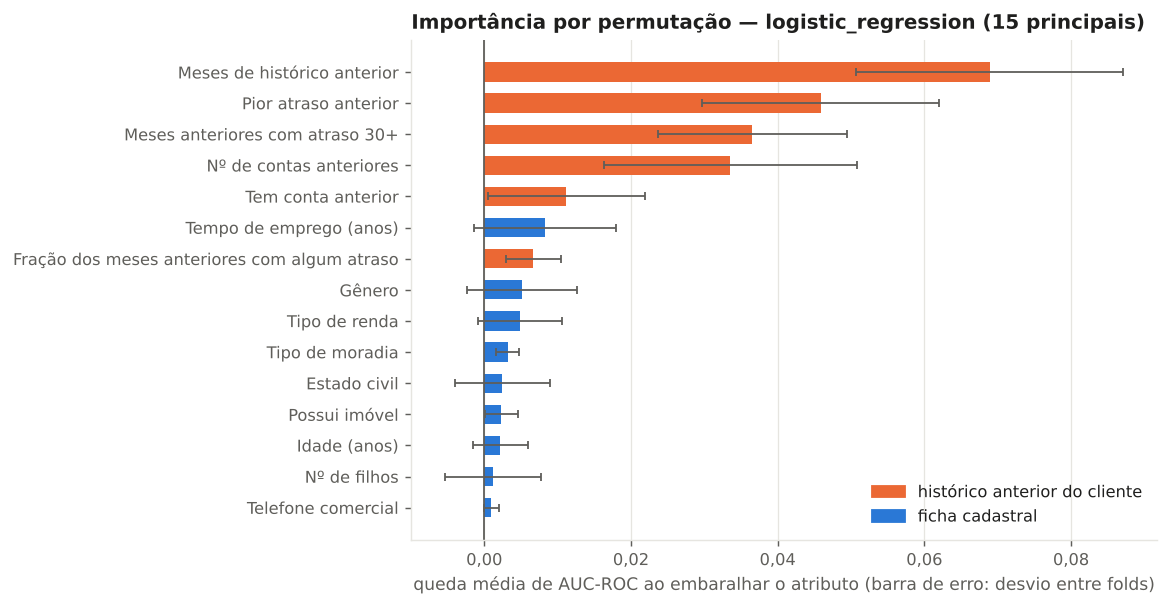

,rotulo,queda_auc_media,desvio_entre_folds
0,Meses de histórico anterior,0.0689,0.0182
1,Pior atraso anterior,0.0459,0.0161
2,Meses anteriores com atraso 30+,0.0366,0.0128
3,Nº de contas anteriores,0.0336,0.0172
4,Tem conta anterior,0.0112,0.0107
5,Tempo de emprego (anos),0.0083,0.0097
6,Fração dos meses anteriores com algum atraso,0.0067,0.0037
7,Gênero,0.0052,0.0075
8,Tipo de renda,0.0049,0.0058
9,Tipo de moradia,0.0032,0.0016


In [9]:
feats = meta["modelos"][ESCOLHIDO]["atributos"]
imp = cv_permutation_importance(modelos[ESCOLHIDO], train, feats, TARGET, n_repeats=5,
                                random_state=RANDOM_STATE)
imp["rotulo"] = imp["atributo"].map(ROTULOS)
imp.to_csv(METRICS / "importancia_permutacao.csv", index=False)

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.4, 5.0))
cores = [COR_MAU if a.startswith("HIST_") else COR_BOM for a in top["atributo"]]
ax.barh(top["rotulo"], top["queda_auc_media"], xerr=top["desvio_entre_folds"], color=cores,
        height=0.62, error_kw=dict(ecolor="#5f5e5a", lw=1, capsize=2))
ax.axvline(0, color="#5f5e5a", lw=1)
ax.set_xlabel("queda média de AUC-ROC ao embaralhar o atributo (barra de erro: desvio entre folds)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.2f}".replace(".", ","))
ax.set_title(f"Importância por permutação — {ESCOLHIDO} (15 principais)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COR_MAU, label="histórico anterior do cliente"),
                   Patch(color=COR_BOM, label="ficha cadastral")], loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "04_importancia_permutacao")
plt.show()
imp[["rotulo", "queda_auc_media", "desvio_entre_folds"]].round(4)

**Leitura.**

- **Cinco das seis variáveis mais importantes são de histórico anterior.** *Meses de
  histórico* lidera (queda de 0,069 de AUC ao ser embaralhada), seguida de *pior atraso
  anterior* (0,046), *meses com atraso de 30+ dias* (0,037) e *número de contas anteriores*
  (0,034).
- **Faz sentido no domínio.** Quem já atrasou 60+ dias tende a repetir (17,7% contra 1,5% na
  EDA). E tempo de relacionamento protege: um cliente com muitos meses de histórico e várias
  contas é alguém a quem o banco já concedeu crédito repetidas vezes sem problema.
- **Da ficha cadastral, pouca coisa pesa.** Tempo de emprego é a primeira (0,008), seguida de
  gênero, tipo de renda, moradia, estado civil e imóvel próprio (0,002 a 0,005), quase todas
  com barra de erro que encosta no zero. **Renda, escolaridade e ocupação têm importância
  nula ou negativa**: o modelo não perde nada sem elas.
- **Ocupação**, que parecia promissora no IV da EDA, não se sustenta fora da amostra. É o
  que se espera de um atributo com muitas categorias pequenas: o IV alto vinha do ruído.

Um cuidado de leitura: as variáveis de histórico são correlacionadas entre si. Quando uma é
embaralhada, as outras compensam parte da perda, então a importância individual de cada uma
está subestimada. O que importa é o bloco, e a evidência mais direta do seu peso é a
comparação entre os dois conjuntos de atributos: AUC de 0,63 sem o histórico e 0,73 com ele,
no teste.

In [10]:
# Segunda opinião: coeficientes da regressão logística (atributos padronizados,
# então os coeficientes são comparáveis entre si). exp(coef) = razão de chances.
lr = modelos["logistic_regression"]
coef = pd.DataFrame({"atributo": lr[:-1].get_feature_names_out(), "coeficiente": lr[-1].coef_[0]})
coef["razao_de_chances"] = np.exp(coef["coeficiente"])
coef = coef.sort_values("coeficiente", key=abs, ascending=False).reset_index(drop=True)
coef.to_csv(METRICS / "coeficientes_regressao_logistica.csv", index=False)
coef.head(12).round(3)

,atributo,coeficiente,razao_de_chances
0,HIST_MONTHS,-0.513,0.599
1,HIST_WORST_STATUS,0.379,1.461
2,HIST_N_ACCOUNTS,-0.341,0.711
3,HIST_MONTHS_30PLUS,0.296,1.344
4,NAME_INCOME_TYPE_Pensioner,0.287,1.333
5,OCCUPATION_TYPE_Core staff,0.257,1.293
6,NAME_FAMILY_STATUS_Widow,0.239,1.270
7,NAME_FAMILY_STATUS_Married,-0.202,0.817
8,NAME_INCOME_TYPE_State servant,-0.202,0.817
9,YEARS_EMPLOYED,-0.194,0.824


**Leitura — os coeficientes do modelo escolhido.** Esta é a vantagem da regressão
logística: cada fator tem um peso com sinal explícito, e cada decisão pode ser explicada a
partir deles. Os atributos numéricos estão padronizados, então a razão de chances se refere
ao aumento de um desvio-padrão:

- **Aumentam o risco:** pior atraso anterior (chances × 1,46), meses anteriores com atraso de
  30+ dias (× 1,34), ser aposentado (× 1,33), ser viúvo (× 1,27).
- **Reduzem o risco:** mais meses de histórico (× 0,60), mais contas anteriores (× 0,71), ser
  casado (× 0,82), ser servidor público (× 0,82), mais tempo de emprego (× 0,82).

Quatro dos cinco maiores coeficientes são de histórico. Os efeitos cadastrais apontam para
o mesmo lado das taxas observadas na EDA (viúvos e aposentados acima da média; casados,
servidores e empregos longos abaixo). Com atributos correlacionados e regularização forte,
o tamanho exato de cada coeficiente deve ser lido com cautela; o sinal e a ordem são
confiáveis.

In [11]:
# Quanto do desempenho depende de atributos sensíveis? Reavalia o modelo escolhido
# na validação cruzada do treino sem gênero e sem gênero + idade + estado civil.
sensiveis = {"todos os atributos": [], "sem gênero": ["CODE_GENDER"],
             "sem gênero, idade e estado civil": ["CODE_GENDER", "AGE_YEARS", "EMPLOYED_SHARE",
                                                  "NAME_FAMILY_STATUS"]}
linhas = []
for rot, fora in sensiveis.items():
    cols = [c for c in feats if c not in fora]
    reduzido = clone(modelos[ESCOLHIDO]).set_params(
        prep=build_preprocessor(cols, scale=ESCOLHIDO in ("logistic_regression", "knn")))
    _, tab = cross_validate_model(reduzido, train, cols, repeats=1)
    linhas.append({"cenário": rot, "atributos": len(cols), "roc_auc_cv": tab["roc_auc"].mean(),
                   "pr_auc_cv": tab["pr_auc"].mean()})
sens = pd.DataFrame(linhas).set_index("cenário")
sens.to_csv(METRICS / "atributos_sensiveis_cv.csv")
sens.round(3)

,atributos,roc_auc_cv,pr_auc_cv
cenário,,,
todos os atributos,26,0.754,0.098
sem gênero,25,0.753,0.095
"sem gênero, idade e estado civil",22,0.753,0.102


**Leitura — atributos sensíveis.** Gênero, idade e estado civil são características
pessoais cujo uso em decisão de crédito é questionável do ponto de vista ético e, em
várias jurisdições, vedado. A tabela mostra que **o modelo não precisa deles**: sem gênero a
AUC passa de 0,754 para 0,753, e sem gênero, idade e estado civil fica também em 0,753. As
diferenças estão muito abaixo do ruído entre folds (±0,03). O modelo entregue usa todos os
atributos, como pede o desafio, mas uma versão para produção pode e deve dispensá-los sem
perda mensurável.

In [12]:
# O modelo funciona dentro de cada safra, ou só está separando contas antigas de recentes?
oof_treino, _ = cross_validate_model(modelos[ESCOLHIDO], train, feats, repeats=1)
faixas_safra = dict(bins=[-61, -44, -28, -10],
                    labels=["antiga (meses −60 a −44)", "intermediária (−43 a −28)", "recente (−27 a −11)"])
linhas = []
for rot, base, esc in [("treino (out-of-fold)", train, oof_treino), ("teste", test, p)]:
    d = base.assign(escore=esc, safra=pd.cut(base["OPEN_MONTH"], **faixas_safra))
    for safra, g in d.groupby("safra", observed=True):
        linhas.append({"conjunto": rot, "safra de abertura": safra, "contas": len(g),
                       "maus": int(g[TARGET].sum()), "% com histórico": 100 * g["HIST_HAS"].mean(),
                       "roc_auc": roc_auc_score(g[TARGET], g["escore"])})
safras = pd.DataFrame(linhas).set_index(["conjunto", "safra de abertura"])
safras.to_csv(METRICS / "desempenho_por_safra.csv")
safras.round(3)

contas  maus  % com histórico  roc_auc
conjunto             safra de abertura                                                
treino (out-of-fold) antiga (meses −60 a −44)     4803    89           35.020    0.679
                     intermediária (−43 a −28)    6468    99           69.171    0.743
                     recente (−27 a −11)          8381   108           80.480    0.790
teste                antiga (meses −60 a −44)     1155    24           35.584    0.632
                     intermediária (−43 a −28)    1683    21           68.033    0.764
                     recente (−27 a −11)          2076    29           82.081    0.748

**Leitura — robustez por safra.** Uma preocupação legítima: como *meses de histórico* pesa
no modelo e contas abertas mais recentemente têm mais histórico disponível, o modelo
poderia estar só separando contas antigas de recentes. A tabela descarta isso. **Dentro de
cada safra** o modelo continua discriminando: AUC de 0,63 a 0,76 no teste e de 0,68 a 0,79
na validação out-of-fold.

Ela também revela uma limitação dos dados. Nas contas mais antigas só 35% têm histórico
anterior, contra 80% ou mais nas recentes, porque a base começa no mês −60 e tudo que
aconteceu antes está cortado. Nessas safras, "sem histórico" muitas vezes significa
"histórico fora da base", e o modelo vai pior. Em produção o banco teria o histórico
completo de cada cliente, uma situação mais parecida com a das safras recentes.

## 5. Implicações práticas

**O que este trabalho diz a quem decide crédito, sem jargão.**

1. **O melhor indicador de quem vai atrasar é quem já atrasou.** Um cliente que teve atraso
   de 60 dias ou mais em outra conta volta a atrasar em cerca de 1 a cada 6 casos; um
   cliente com histórico limpo, em 1 a cada 170. Nenhuma informação da ficha chega perto
   disso. A primeira providência é garantir que o histórico interno do cliente esteja na
   mesa de quem analisa o pedido.

2. **A ficha cadastral, sozinha, ajuda pouco.** Renda, idade, escolaridade e profissão quase
   não separam bons de maus pagadores nesta base. Regras do tipo "só aprova acima de tal
   renda" não encontram respaldo nos dados. O que ajuda um pouco é estabilidade: tempo no
   emprego atual, estado civil e tipo de vínculo.

3. **O modelo serve para ordenar pedidos, não para decidir sozinho.** Ele separa bem os
   extremos. Uso recomendado, em três faixas:
   - **metade de menor risco** (0,61% de maus): aprovação automática;
   - **faixa intermediária**: aprovação com limite inicial conservador;
   - **5% de maior risco** (8,9% de maus): análise manual ou recusa.

4. **O ponto de corte é uma decisão de negócio.** Recusar os 5% de maior risco evita 30% da
   inadimplência ao custo de 10 bons clientes recusados para cada mau barrado. Se a perda
   com um inadimplente for maior que o lucro com 10 bons clientes, o corte se paga. A tabela
   de política de corte permite refazer a conta para qualquer nível.

5. **Cliente novo é o ponto cego.** Quem pede a primeira conta tem risco bem maior
   (2,1% de maus contra 1,2%) e é onde o modelo menos enxerga. Para esse público, vale mais investir
   em **informação externa** (bureau de crédito, cadastro positivo, open finance) do que em
   algoritmos mais sofisticados, e começar com limites baixos que crescem conforme o
   comportamento.

6. **Gênero, idade e estado civil podem sair do modelo** sem perda de desempenho, o que
   elimina um risco regulatório e reputacional a custo zero.

## 6. Limitações

**Onde o modelo falha.**

- **Poder de discriminação moderado.** AUC de 0,73 no teste, com intervalo de 0,66 a 0,80.
  No limiar de referência, 84% dos maus pagadores ainda são aprovados. O modelo reduz a
  inadimplência, não a elimina.
- **Poucos eventos.** São 370 maus em toda a base e 74 no teste. As estimativas têm margem
  de erro larga e a diferença entre os três melhores algoritmos não é mensurável.
- **Fraco para clientes novos** (AUC 0,66), como discutido acima.
- **Escore não calibrado.** Os pesos de classe distorcem a escala: o escore ordena o risco,
  mas não é uma probabilidade de inadimplência. Para precificação ou provisão seria preciso
  calibrá-lo (por exemplo, com regressão isotônica).
- **Escolha por desempate.** A Random Forest teve AUC média um pouco maior na validação
  cruzada (0,761 contra 0,751) e barrou mais maus no topo do ranking do treino (30% contra 25%
  no corte de 5%). A diferença está dentro do ruído e não se repetiu no teste; a regressão
  logística foi escolhida por ser explicável. Se a explicabilidade não for exigência, a
  Random Forest é uma alternativa equivalente.

**Limitações dos dados.**

- **Identidade do cliente inferida.** Não há identificador de pessoa; fichas idênticas em 17
  atributos foram tratadas como o mesmo cliente. Com CPF ou equivalente, o histórico seria
  exato.
- **Histórico truncado.** A base cobre 60 meses e `credit_record.csv` tem exatamente o
  número máximo de linhas de uma planilha Excel, sinal de corte na origem. Parte do
  histórico real não está nos dados.
- **Só contas com histórico têm rótulo.** As 402 mil solicitações sem histórico ficaram de
  fora. O modelo aprendeu com quem recebeu o cartão; aplicá-lo a toda a fila de pedidos supõe que os
  recusados se comportariam de forma parecida (problema conhecido como inferência de
  rejeitados).
- **Sem valores.** Não há limite, saldo nem valor em atraso. Não é possível estimar perda
  financeira nem otimizar o corte em dinheiro.
- **Sem data de calendário.** Só há meses relativos à extração; não dá para controlar
  sazonalidade nem ciclo econômico.

**O que fazer com mais tempo ou mais dados.**

1. Enriquecer com bureau de crédito e dados transacionais, especialmente para clientes novos.
2. Validar em safra futura (*out-of-time*): treinar com contas antigas e testar nas mais
   recentes, simulando o uso real.
3. Calibrar o escore e definir o corte por valor esperado, com perda e margem reais.
4. Avaliar equidade por grupo (taxas de aprovação e de erro por gênero e faixa etária).
5. Monitorar estabilidade do escore e da taxa de maus depois da implantação.
6. Testar XGBoost/LightGBM e SHAP. Dado o empate entre os algoritmos já testados, o ganho
   esperado é pequeno; o gargalo está nos dados, não no algoritmo.

In [13]:
resumo = {
    "modelo_escolhido": ESCOLHIDO,
    "limiar": limiar,
    "teste": {k: float(v) for k, v in resultados[ESCOLHIDO].items()},
    "teste_n_contas": int(len(test)), "teste_n_maus": int(y_test.sum()),
    "matriz_confusao": {"bons_aprovados": int(cm[0, 0]), "bons_reprovados": int(cm[0, 1]),
                        "maus_aprovados": int(cm[1, 0]), "maus_barrados": int(cm[1, 1])},
}
json.dump(resumo, open(METRICS / "metricas_teste.json", "w"), indent=2)
print(json.dumps(resumo, indent=2))

{
  "modelo_escolhido": "logistic_regression",
  "limiar": 0.7675536413627331,
  "teste": {
    "accuracy": 0.9723239723239723,
    "balanced_accuracy": 0.5734364529819076,
    "precision": 0.13953488372093023,
    "recall": 0.16216216216216217,
    "f1": 0.15,
    "roc_auc": 0.7337963480008936,
    "pr_auc": 0.0837717012494751,
    "ks": 0.3720292606656243,
    "roc_auc_ic95_inf": 0.6622429070312277,
    "roc_auc_ic95_sup": 0.7988910914023954,
    "roc_auc_cv": 0.7512628263803341,
    "limiar": 0.7675536413627331
  },
  "teste_n_contas": 4914,
  "teste_n_maus": 74,
  "matriz_confusao": {
    "bons_aprovados": 4766,
    "bons_reprovados": 74,
    "maus_aprovados": 62,
    "maus_barrados": 12
  }
}
